# Extension 2: Does UCL discrimination survive later-time evaluation?

Train **2017–2023**, evaluate **2024–2025**, then test **2026** using the same
frozen model. The endpoint, 22 candidate predictors, XGBoost settings, training
CV/selection algorithms, GAM window procedure and ROC-AUC remain those of
Extension 1. All fitted quantities are learned again from training only.

[Methods](../../docs/kang_ucl_chronological_methods.md) ·
[Configuration](../../config/kang_ucl_chronological.yaml)

This is retrospective. The 2026 test is locked within this experiment; the year
has appeared elsewhere in the project and is not prospective confirmation.
This notebook only reads results.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'config/kang_ucl_chronological.yaml').exists())
R=ROOT/'reports/kang_ucl_chronological';T=R/'tables'
display(pd.Series(json.loads((R/'verification.json').read_text())))
freeze=json.loads((R/'development_freeze.json').read_text())
display(pd.DataFrame(freeze['roles']).T)
print('Training freeze:',freeze['frozen_at_utc'])

prior_files_unchanged                                                         3773
endpoint_unchanged                                                            True
database_unchanged                                                            True
training_cutoff                                                         2023-12-31
source_cutoff                                                           2026-10-20
later_access_after_freeze                                                     True
no_later_refits                                                               True
no_cross_period_event_sharing                                                 True
same_parent_functions                                                         True
predictors                       [age_at_appearance, total_pitches, innings_pit...
checks                           [{'role': 'starter', 'period': 'training', 'st...
dtype: object

,status,signature,selected_window,features
starter,complete,eae227ea040abb62aebfe9b4834346bc54aad8d6d8aa1e...,16,"[age_at_appearance, kang_velocity_sd, ff_usage..."
reliever,complete,ebeed2ec5f36c573305754e6ad70ac898e960500c4eb8d...,15,"[age_at_appearance, kang_release_abs_x_avg, re..."


Training freeze: 2026-11-10T18:59:15.831334+00:00


## Cohort support and follow-up

Games are split solely by dates. Pitchers can recur in later seasons; games,
pitcher-seasons and positive injury events cannot cross periods. Fixed season
eligibility and retrospective roles are inherited from the parent.

The verified injury observation cutoff is 2026-10-20. Negative labels require
the selected calendar horizon to finish by that cutoff. Observed positives are
retained; unresolved late negatives remain censored. Source uncertainties are
reported without altering adjudication or pooling roles.

In [2]:
display(pd.read_csv(T/'cohort_support.csv'))
uncertain=pd.read_csv(T/'test_endpoint_uncertainty.csv')
display(uncertain.groupby(['evidence_category','endpoint_primary','in_model_cohort'],dropna=False).size().rename('events').reset_index())
display(pd.read_csv(T/'validation_checks.csv'))

,role,period,pitcher_games,pitcher_seasons,unique_pitchers,ucl_events,first_game,last_game,eligible_games,censored_games,...,prevalence,window,scored_games,roc_auc,ci_low,ci_high,valid_bootstraps,brier,mean_risk_bias,small_event_support
0,starter,training,25675,1227,502,23,2017-04-02,2023-10-01,25675,0,...,0.002571,16,25675,1.000000,1.000000,1.000000,500,0.000011,0.000390,False
1,starter,validation,7543,340,245,13,2024-03-20,2025-09-28,7543,0,...,0.004773,16,7543,0.532022,0.427090,0.640478,500,0.004985,-0.003428,False
2,starter,test,3830,166,166,6,2026-03-25,2026-09-27,3830,0,...,0.004700,16,3830,0.642081,0.505071,0.788534,499,0.005664,-0.001459,False
3,reliever,training,88220,2698,1162,28,2017-04-02,2023-10-01,88220,0,...,0.001576,15,88220,1.000000,1.000000,1.000000,500,0.000028,0.000478,False
4,reliever,validation,26695,768,558,6,2024-03-20,2025-09-28,26695,0,...,0.000974,15,26695,0.475277,0.196481,0.758515,497,0.001056,-0.000436,False
5,reliever,test,13421,403,403,9,2026-03-25,2026-09-27,13421,0,...,0.002384,15,13421,0.401559,0.300780,0.514404,500,0.002472,-0.001590,False


,evidence_category,endpoint_primary,in_model_cohort,events
0,ambiguous_elbow,False,False,5
1,broader_elbow,False,False,76
2,confirmed_official_documentation,False,False,3
3,confirmed_official_documentation,True,False,2
4,confirmed_official_documentation,True,True,2
5,confirmed_procedure_supported,False,False,2
6,confirmed_procedure_supported,True,False,4
7,confirmed_procedure_supported,True,True,13
8,forearm_without_ucl_confirmation,False,False,39
9,other_or_unknown_injury,False,False,51


,role,period,status,games,known_labels,independent_auc,no_cross_period_games,no_cross_period_pitcher_seasons,no_cross_period_positive_events
0,starter,training,passed,25675,25675,1.000000,True,True,True
1,starter,validation,passed,7543,7543,0.532022,True,True,True
2,starter,test,passed,3830,3830,0.642081,True,True,True
3,reliever,training,passed,88220,88220,1.000000,True,True,True
4,reliever,validation,passed,26695,26695,0.475277,True,True,True
5,reliever,test,passed,13421,13421,0.401559,True,True,True


## Training-only window development

Every 7–49-day candidate uses five-fold training CV. The exact parent functions
produce the smoothed AUC curve, slope band and rounded midpoint. Disconnected
bands do not identify a unique optimum. A missing band receives no fallback.
These CV curves use training games, not validation or test scores.

,role,lower,upper,selected,segments,maximum_slope,status,selected_day_in_band,interpretable_single_band
0,starter,11.50,21.36,16,3,0.0226,inferred_with_disclosed_gam_settings,False,False
1,reliever,14.26,15.17,15,1,0.0143,inferred_with_disclosed_gam_settings,True,True


,window,cv_auc,fold_sd,folds,games,positive_games,role
0,7,0.807368,0.142521,5,25675,42,starter
1,8,0.894232,0.060123,5,25675,43,starter
2,9,0.891089,0.056262,5,25675,46,starter
3,10,0.891089,0.056262,5,25675,46,starter
4,11,0.898255,0.057066,5,25675,47,starter
...,...,...,...,...,...,...,...
81,45,0.991171,0.006846,5,88220,304,reliever
82,46,0.991171,0.006846,5,88220,304,reliever
83,47,0.988310,0.008697,5,88220,308,reliever
84,48,0.986656,0.008532,5,88220,311,reliever


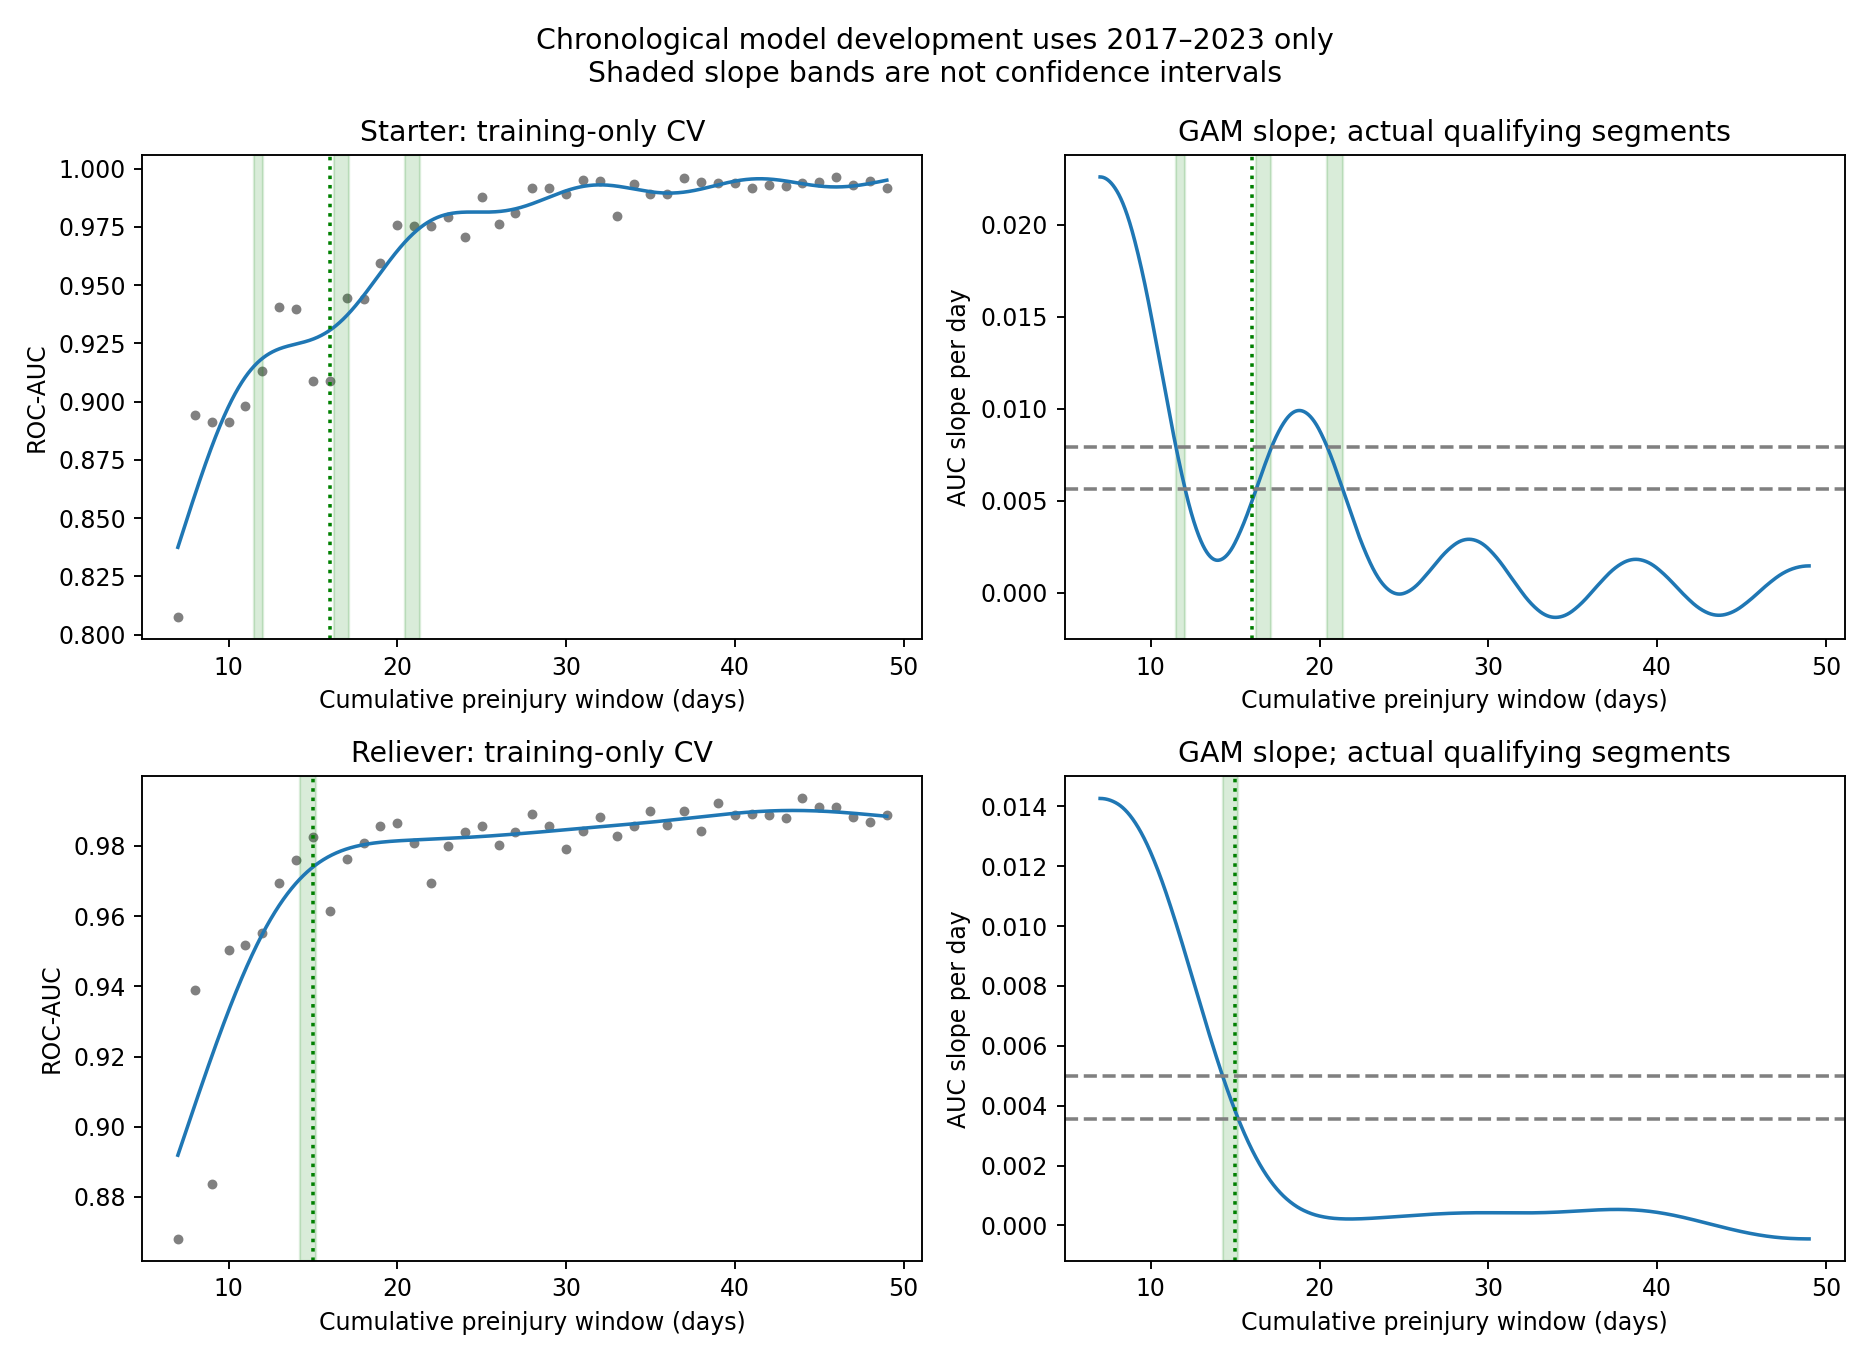

In [3]:
display(pd.read_csv(T/'window_selection.csv'))
display(pd.read_csv(T/'training_window_performance.csv'))
display(Image(filename=str(R/'figures/01_training_windows.png')))

## Random-game versus temporal discrimination

Extension 1 is read only as the comparator. Both later periods use the model
fitted on 2017–2023, with no updating after validation. Intervals use the same
500 pitcher-season bootstrap attempts; interpret them alongside event counts.
Conditional intervals with few events do not establish population-level stability.

,role,random_comparator_roc_auc,random_comparator_ci_low,random_comparator_ci_high,random_comparator_positive_games,random_comparator_represented_events,random_comparator_valid_bootstraps,validation_roc_auc,validation_ci_low,validation_ci_high,...,validation_represented_events,validation_valid_bootstraps,validation_delta_from_random,test_roc_auc,test_ci_low,test_ci_high,test_positive_games,test_represented_events,test_valid_bootstraps,test_delta_from_random
0,reliever,0.9868,0.9797,0.9929,58.0,29.0,500.0,0.4753,0.1965,0.7585,...,6.0,497.0,-0.5115,0.4016,0.3008,0.5144,32.0,9.0,500.0,-0.5853
1,starter,0.9559,0.9269,0.9877,57.0,30.0,500.0,0.5320,0.4271,0.6405,...,13.0,500.0,-0.4239,0.6421,0.5051,0.7885,18.0,6.0,499.0,-0.3138


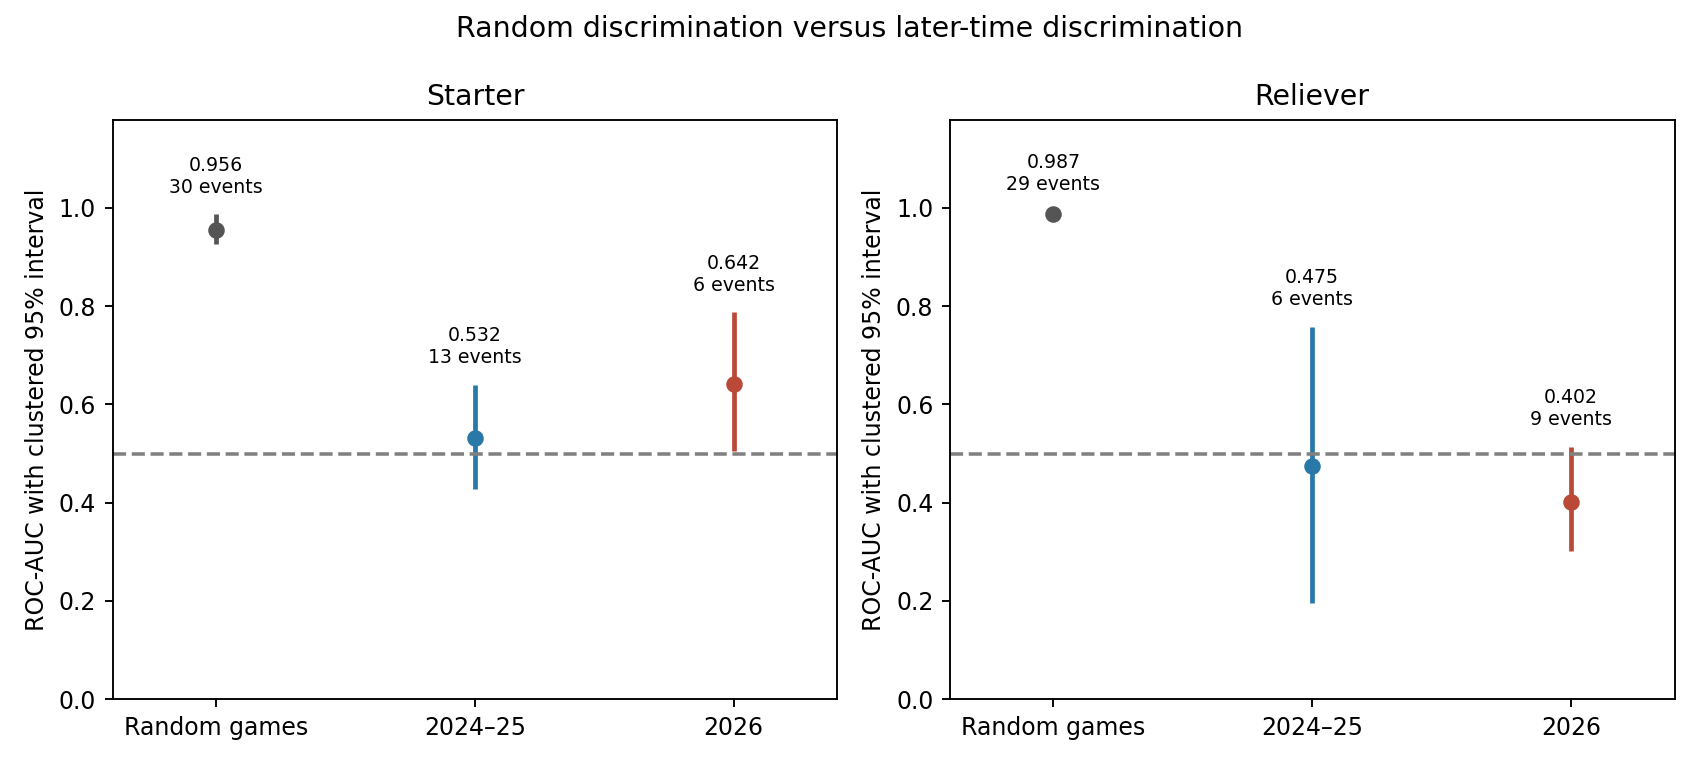

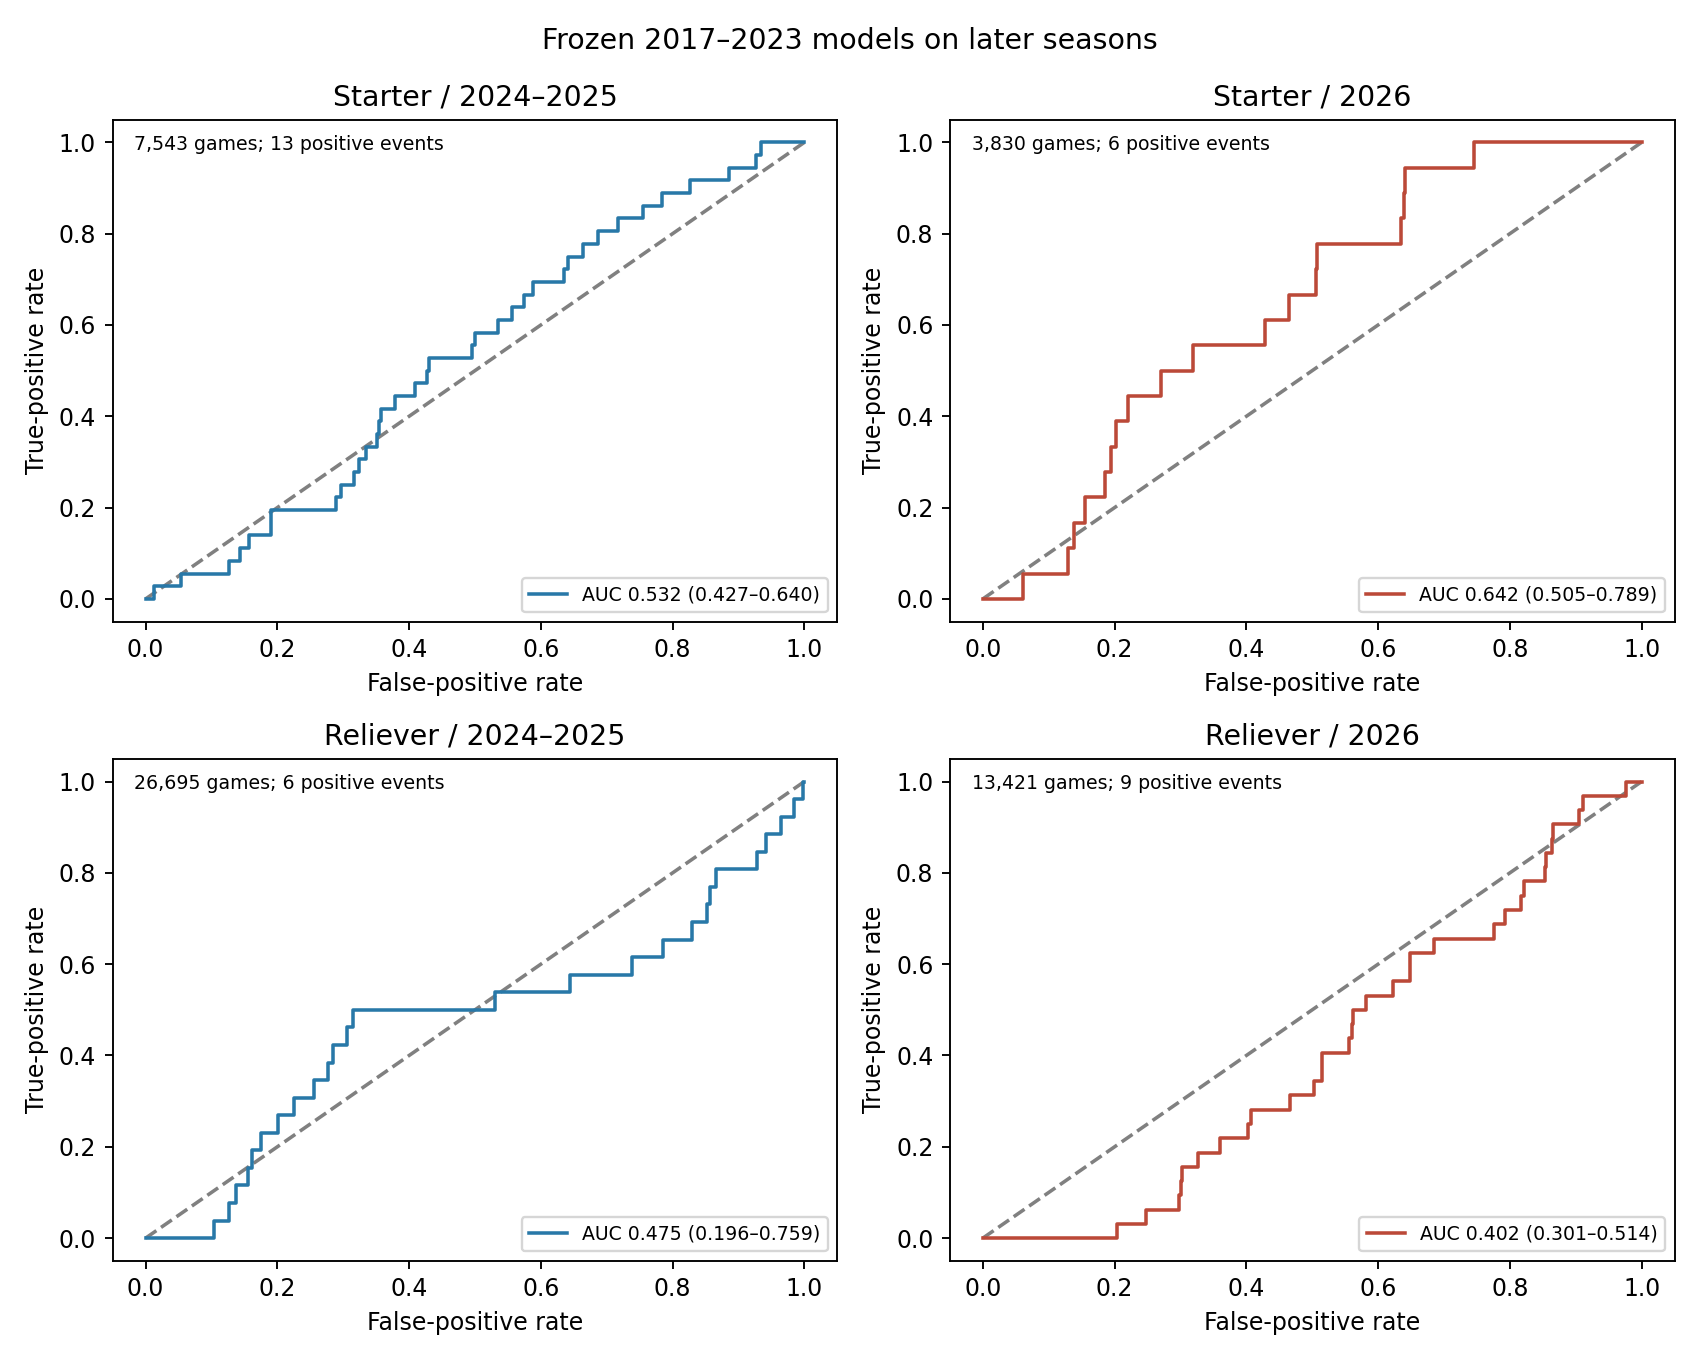

,role,period,training_pitcher_status,scored_games,eligible_games,pitchers,pitcher_seasons,positive_games,represented_events,prevalence,roc_auc,small_event_support
0,starter,validation,seen,5440,5440,148,219,21,8,0.00386,0.48360,False
1,starter,validation,unseen,2103,2103,97,121,15,5,0.00713,0.57481,False
2,starter,test,seen,1887,1887,72,72,3,1,0.00159,0.58953,True
3,starter,test,unseen,1943,1943,94,94,15,5,0.00772,0.61909,False
4,reliever,validation,seen,19312,19312,331,484,18,4,0.00093,0.34585,True
5,reliever,validation,unseen,7383,7383,227,284,8,2,0.00108,0.78146,True
6,reliever,test,seen,7126,7126,171,171,12,3,0.00168,0.39181,True
7,reliever,test,unseen,6295,6295,232,232,20,6,0.00318,0.39731,False


In [4]:
display(pd.read_csv(T/'primary_comparison.csv').round(4))
display(Image(filename=str(R/'figures/03_auc_comparison.png')))
display(Image(filename=str(R/'figures/02_temporal_roc.png')))
display(pd.read_csv(T/'seen_unseen_pitchers.csv').round(5))

## Model reliance and descriptive drift

Gain is calculated from training-only bootstrap refits. The comparison concerns
model reliance, not injury mechanisms. Score distributions include all scored
cohort games; training scores are in-sample. Predictor shifts are summarized
without adapting, recalibrating or retraining the model.

Reliability bins are learned from training scores. Class weighting means the
scores should not be assumed to estimate absolute UCL risk.

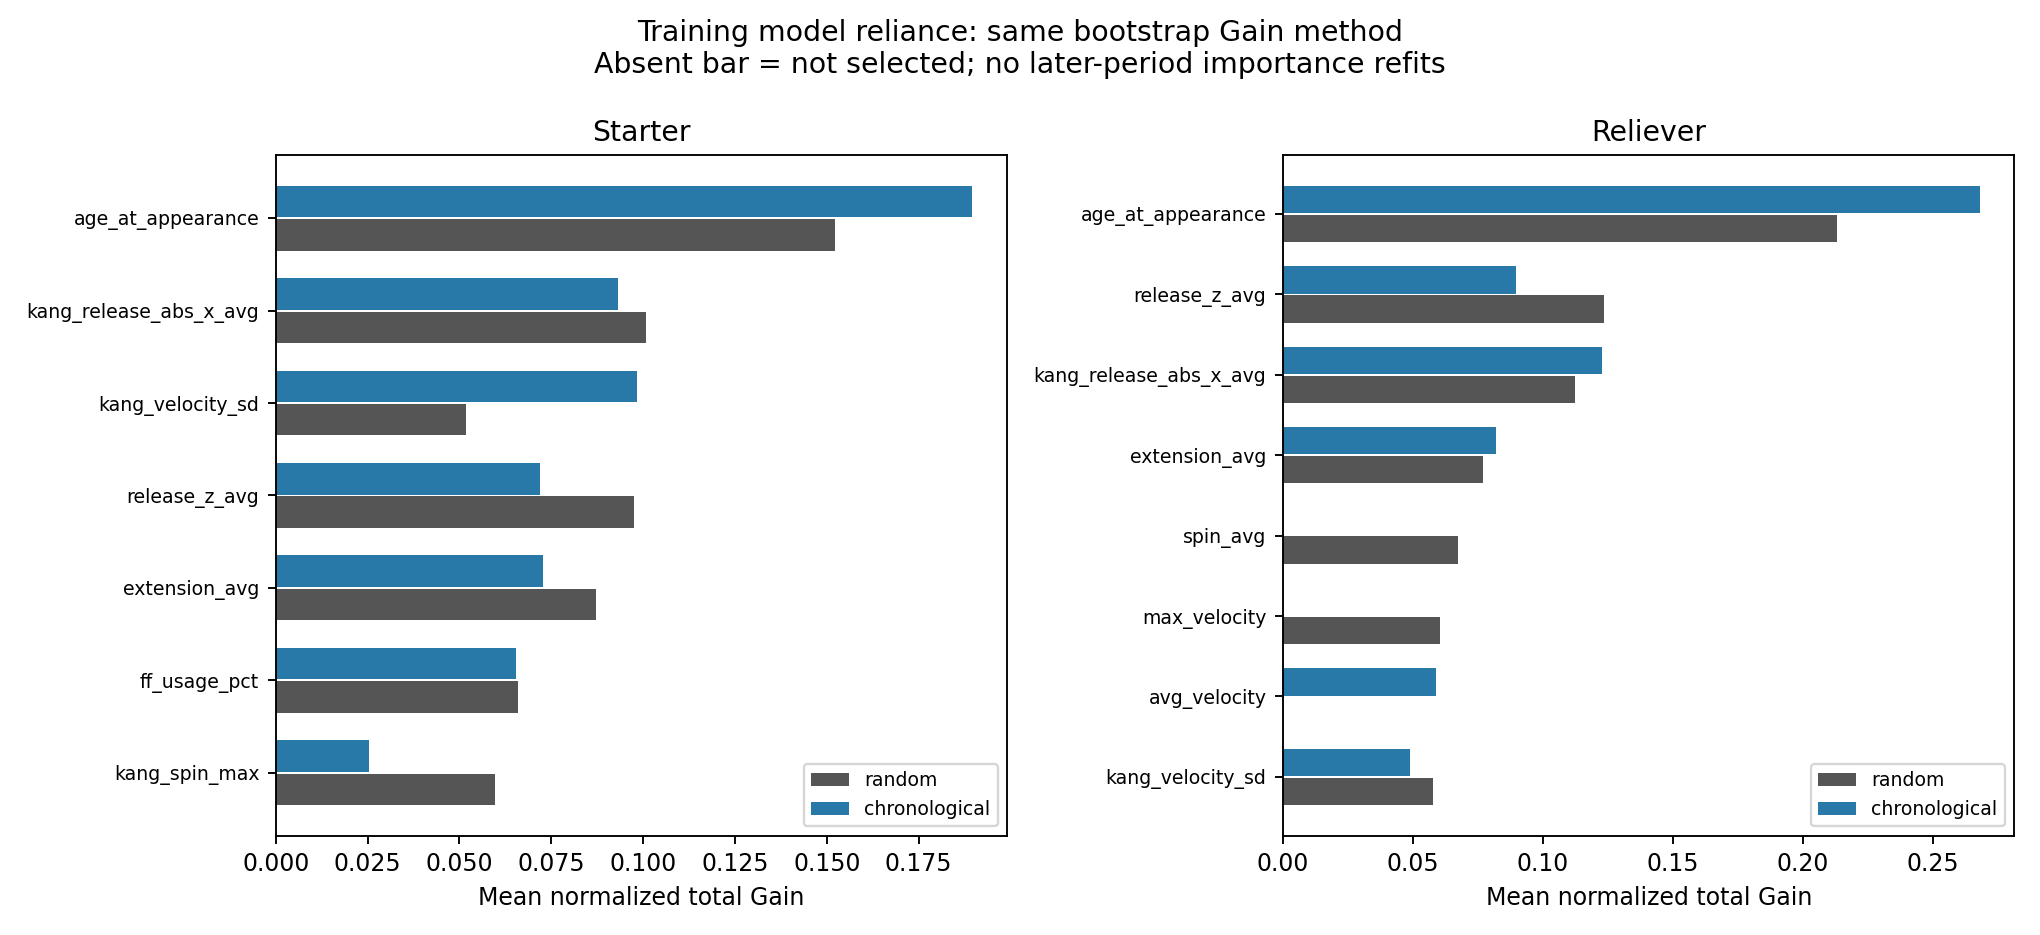

,feature,role,domain,random_rank,random_mean_gain,random_gain_sd,random_valid_refits,chronological_rank,chronological_mean_gain,chronological_gain_sd,chronological_valid_refits,rank_change
0,age_at_appearance,starter,context,1.0,0.152355,0.054638,500.0,1.0,0.189644,0.092675,500.0,0.0
1,total_pitches,starter,workload,16.0,0.019686,0.012836,500.0,9.0,0.049087,0.032690,500.0,-7.0
2,innings_pitched,starter,workload,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,batters_faced,starter,workload,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,avg_velocity,starter,velocity,12.0,0.040044,0.019018,500.0,NaN,NaN,NaN,NaN,NaN
5,max_velocity,starter,velocity,NaN,NaN,NaN,NaN,8.0,0.052465,0.037122,500.0,NaN
6,kang_velocity_sd,starter,velocity,8.0,0.051761,0.023932,500.0,2.0,0.098346,0.062005,500.0,-6.0
7,spin_avg,starter,spin,10.0,0.049065,0.026928,500.0,7.0,0.057429,0.034188,500.0,-3.0
8,kang_spin_max,starter,spin,6.0,0.059783,0.029953,500.0,15.0,0.025267,0.019356,500.0,9.0
9,kang_spin_sd,starter,spin,11.0,0.044225,0.021742,500.0,14.0,0.028201,0.021929,500.0,3.0


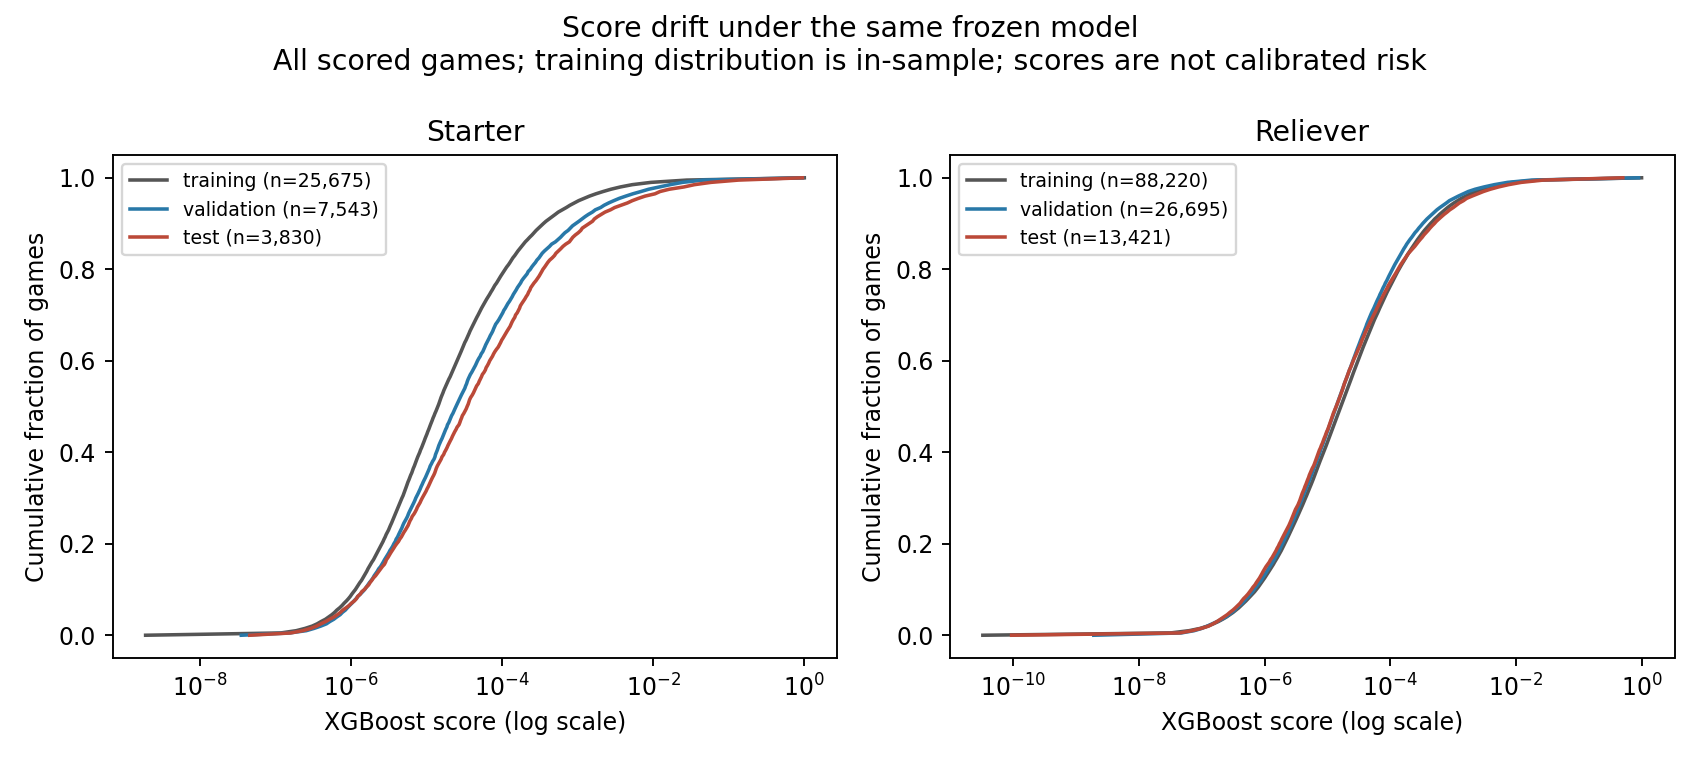

,role,period,scored_games,mean,sd,q1,q10,q25,q50,q75,q90,q99
0,starter,training,25675,0.002961,0.050705,1.886907e-07,1.142810e-06,0.000004,0.000014,0.000071,0.000352,0.009339
1,starter,validation,7543,0.001345,0.014753,2.557869e-07,1.516352e-06,0.000005,0.000025,0.000147,0.000944,0.024363
2,starter,test,3830,0.003240,0.030947,2.305036e-07,1.503082e-06,0.000006,0.000034,0.000224,0.001419,0.058001
3,reliever,training,88220,0.002054,0.039972,6.312254e-08,7.412118e-07,0.000003,0.000016,0.000089,0.000437,0.008767
4,reliever,validation,26695,0.000538,0.009075,7.583811e-08,6.776506e-07,0.000003,0.000014,0.000072,0.000328,0.007372
5,reliever,test,13421,0.000794,0.009323,7.015174e-08,6.170919e-07,0.000003,0.000014,0.000082,0.000504,0.012137


,role,period,feature,n_observed,missing_fraction,mean,sd,q25,median,q75,standardized_mean_difference
0,starter,training,age_at_appearance,25675,0.000000,28.796819,3.895296,25.829415,28.194966,31.307967,0.000000
1,starter,training,total_pitches,25675,0.000000,84.614450,21.598706,78.000000,90.000000,98.000000,0.000000
2,starter,training,innings_pitched,25675,0.000000,5.141577,1.643464,4.333333,5.333333,6.000000,0.000000
3,starter,training,batters_faced,25675,0.000000,21.769932,5.703155,20.000000,23.000000,25.000000,0.000000
4,starter,training,avg_velocity,25638,0.001441,88.287911,2.641697,86.655025,88.382542,90.039936,0.000000
...,...,...,...,...,...,...,...,...,...,...,...
127,reliever,test,kc_usage_pct,13421,0.000000,0.006953,0.045537,0.000000,0.000000,0.000000,-0.147492
128,reliever,test,fc_usage_pct,13421,0.000000,0.078174,0.151555,0.000000,0.000000,0.100000,0.060807
129,reliever,test,si_usage_pct,13421,0.000000,0.201386,0.230632,0.000000,0.125000,0.333333,0.084894
130,reliever,test,cu_usage_pct,13421,0.000000,0.041272,0.097442,0.000000,0.000000,0.000000,-0.115486


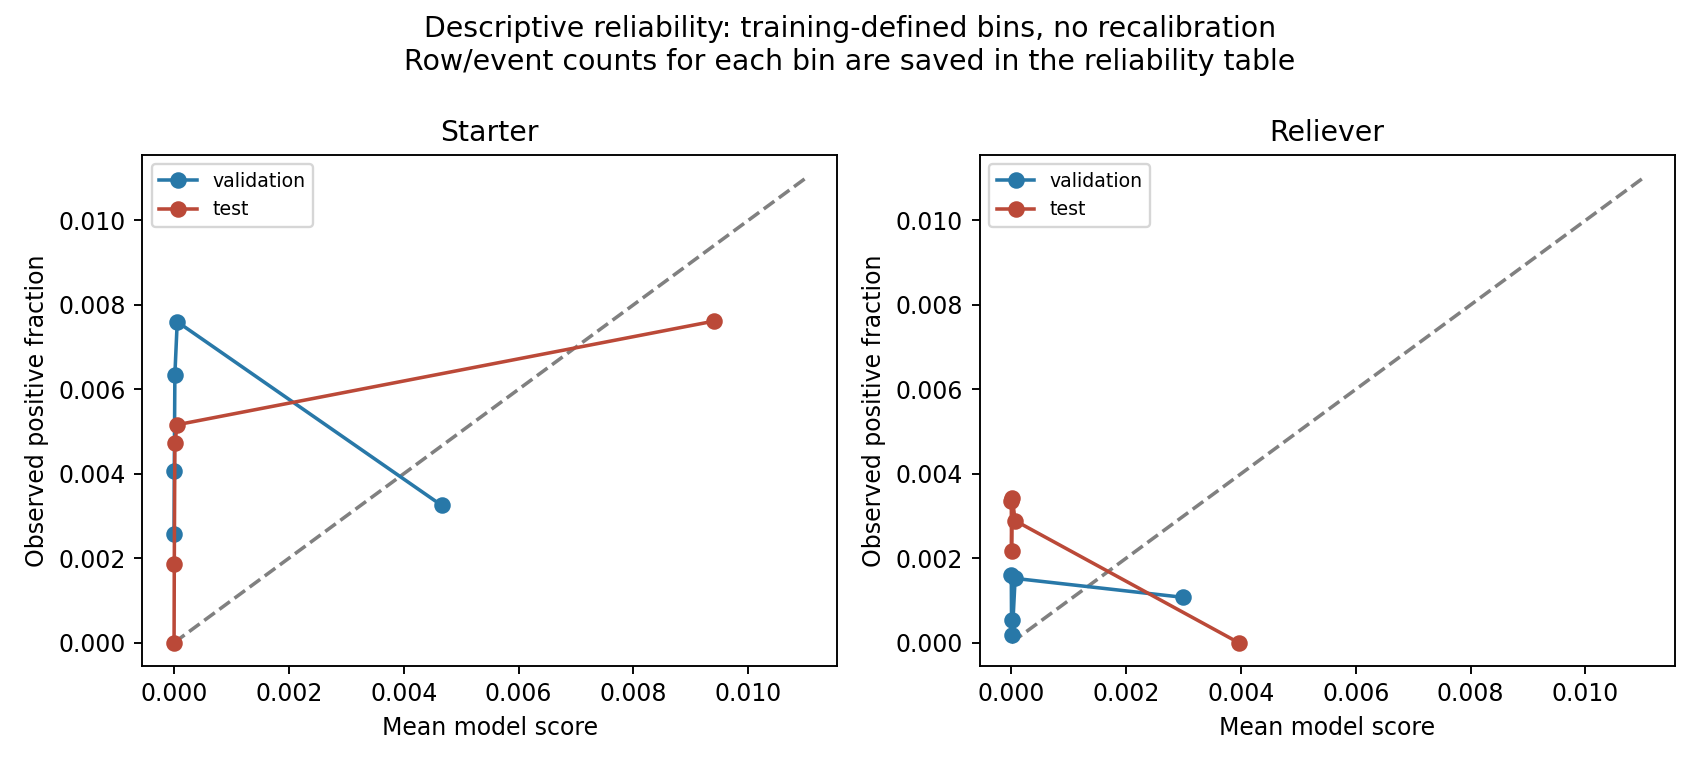

,role,period,bin,games,positive_games,events,mean_score,observed_rate,bin_source
0,starter,training,0,5135,0,0,1.196060e-06,0.000000,training score quantiles
1,starter,training,1,5135,0,0,4.904869e-06,0.000000,training score quantiles
2,starter,training,2,5135,0,0,1.488528e-05,0.000000,training score quantiles
3,starter,training,3,5135,0,0,5.425131e-05,0.000000,training score quantiles
4,starter,training,4,5135,66,23,1.472816e-02,0.012853,training score quantiles
5,starter,validation,0,1166,3,2,1.208196e-06,0.002573,training score quantiles
6,starter,validation,1,1228,5,4,4.933339e-06,0.004072,training score quantiles
7,starter,validation,2,1418,9,5,1.510797e-05,0.006347,training score quantiles
8,starter,validation,3,1579,12,8,5.612632e-05,0.007600,training score quantiles
9,starter,validation,4,2152,7,5,4.659665e-03,0.003253,training score quantiles


In [5]:
display(Image(filename=str(R/'figures/04_importance_comparison.png')))
display(pd.read_csv(T/'feature_importance_comparison.csv'))
display(Image(filename=str(R/'figures/05_score_drift.png')))
display(pd.read_csv(T/'score_distribution.csv'))
display(pd.read_csv(T/'predictor_drift.csv'))
display(Image(filename=str(R/'figures/06_reliability.png')))
display(pd.read_csv(T/'reliability.csv'))

## Synthesis and limits

The conclusion follows the interpretation policy frozen before later-period
access. A weak chronological result is informative. No alternative windows,
seeds, predictors, cases or models are substituted to improve it. The report
distinguishes chance-compatible estimates, small event support, window ambiguity,
retrospective endpoint limitations and incomplete follow-up.

In [6]:
display(Markdown((R/'summary.md').read_text()))

# Extension 2 — chronological UCL evaluation

**Conclusion: Temporal discrimination does not clearly persist.**

The only major design change is calendar separation. All fitted choices use 2017–2023. The same frozen models score 2024–2025 and 2026; neither later period chooses a model, window or feature. The random-game comparator is archived Extension 1.

## Cohort and positive-event support

| role     | period     |   pitcher_games |   eligible_games |   censored_games |   pitcher_seasons |   unique_pitchers |   ucl_events |   represented_events |   positive_games |   negative_games |   prevalence |
|:---------|:-----------|----------------:|-----------------:|-----------------:|------------------:|------------------:|-------------:|---------------------:|-----------------:|-----------------:|-------------:|
| starter  | training   |           25675 |            25675 |                0 |              1227 |               502 |           23 |                   23 |               66 |            25609 |     0.002571 |
| starter  | validation |            7543 |             7543 |                0 |               340 |               245 |           13 |                   13 |               36 |             7507 |     0.004773 |
| starter  | test       |            3830 |             3830 |                0 |               166 |               166 |            6 |                    6 |               18 |             3812 |     0.0047   |
| reliever | training   |           88220 |            88220 |                0 |              2698 |              1162 |           28 |                   28 |              139 |            88081 |     0.001576 |
| reliever | validation |           26695 |            26695 |                0 |               768 |               558 |            6 |                    6 |               26 |            26669 |     0.000974 |
| reliever | test       |           13421 |            13421 |                0 |               403 |               403 |            9 |                    9 |               32 |            13389 |     0.002384 |

Pitcher-games are the screened cohort; eligible games have observed labels for the selected window. Cohort events and events represented by positive games are distinct. Source observation ends **2026-10-20**. Late negative horizons beyond that date remain censored. First-event and regular-season injury framing remain inherited.

At the selected 16/15-day horizons, 0 test games require administrative censoring. The last regular-season game is 2026-09-27; the source cutoff is 2026-10-20. Administrative maturity does not guarantee complete diagnosis/procedure confirmation. The source has 21 accepted 2026 UCL episodes, of which 15 enter the benchmark-compatible cohort. The audit also retains 33 probable-supplemental episodes and 6 episodes with timing/date exclusions; these are not promoted to confirmed outcomes. Unresolved IL absence is distinct from uncertain UCL identity. Later source confirmation could change retrospective ascertainment; no such confirmation is invented.

## Windows and discrimination

| role     | period            |   roc_auc |   ci_low |   ci_high |   represented_events |   valid_bootstraps |
|:---------|:------------------|----------:|---------:|----------:|---------------------:|-------------------:|
| starter  | random_comparator |    0.9559 |   0.9269 |    0.9877 |                   30 |                500 |
| starter  | validation        |    0.532  |   0.4271 |    0.6405 |                   13 |                500 |
| starter  | test              |    0.6421 |   0.5051 |    0.7885 |                    6 |                499 |
| reliever | random_comparator |    0.9868 |   0.9797 |    0.9929 |                   29 |                500 |
| reliever | validation        |    0.4753 |   0.1965 |    0.7585 |                    6 |                497 |
| reliever | test              |    0.4016 |   0.3008 |    0.5144 |                    9 |                500 |

**Starter window:** 16 days; slope envelope 11.50–21.36, 3 segment(s), midpoint inside a segment: False. This checks band shape, not window-selection stability across independent samples.

Starter validation: AUC 0.532 (0.427–0.640), -0.424 versus random 0.956; 13 represented events, 36 positive games; 0 administratively censored games.

Starter test: AUC 0.642 (0.505–0.789), -0.314 versus random 0.956; 6 represented events, 18 positive games; 0 administratively censored games.

Starter leading chronological predictors: age_at_appearance, kang_velocity_sd, kang_release_abs_x_avg, extension_avg, release_z_avg. Shared top-five with random: age_at_appearance, kang_release_abs_x_avg, release_z_avg, extension_avg. Gain is model reliance, not causation.

**Reliever window:** 15 days; slope envelope 14.26–15.17, 1 segment(s), midpoint inside a segment: True. This checks band shape, not window-selection stability across independent samples.

Reliever validation: AUC 0.475 (0.196–0.759), -0.512 versus random 0.987; 6 represented events, 26 positive games; 0 administratively censored games.

Reliever test: AUC 0.402 (0.301–0.514), -0.585 versus random 0.987; 9 represented events, 32 positive games; 0 administratively censored games.

Reliever leading chronological predictors: age_at_appearance, kang_release_abs_x_avg, release_z_avg, extension_avg, avg_velocity. Shared top-five with random: age_at_appearance, kang_release_abs_x_avg, release_z_avg, extension_avg. Gain is model reliance, not causation.

The same 500 pitcher-season bootstrap attempts yield conditional intervals; degenerate draws are omitted and their valid count is reported. A small number of events limits inference even when intervals appear narrow. Training CV remains random within training, as required; its window curve is not a later-time performance estimate.

In-sample training AUCs: starter 1.000, reliever 1.000. These are fit diagnostics, not independent evaluation. The comparison with later-period estimates does not isolate a specific cause of any generalization gap.

## Seen and unseen pitchers

| role     | period     | training_pitcher_status   |   scored_games |   eligible_games |   pitchers |   pitcher_seasons |   positive_games |   represented_events |   prevalence |   roc_auc | small_event_support   |
|:---------|:-----------|:--------------------------|---------------:|-----------------:|-----------:|------------------:|-----------------:|---------------------:|-------------:|----------:|:----------------------|
| starter  | validation | seen                      |           5440 |             5440 |        148 |               219 |               21 |                    8 |      0.00386 |   0.4836  | False                 |
| starter  | validation | unseen                    |           2103 |             2103 |         97 |               121 |               15 |                    5 |      0.00713 |   0.57481 | False                 |
| starter  | test       | seen                      |           1887 |             1887 |         72 |                72 |                3 |                    1 |      0.00159 |   0.58953 | True                  |
| starter  | test       | unseen                    |           1943 |             1943 |         94 |                94 |               15 |                    5 |      0.00772 |   0.61909 | False                 |
| reliever | validation | seen                      |          19312 |            19312 |        331 |               484 |               18 |                    4 |      0.00093 |   0.34585 | True                  |
| reliever | validation | unseen                    |           7383 |             7383 |        227 |               284 |                8 |                    2 |      0.00108 |   0.78146 | True                  |
| reliever | test       | seen                      |           7126 |             7126 |        171 |               171 |               12 |                    3 |      0.00168 |   0.39181 | True                  |
| reliever | test       | unseen                    |           6295 |             6295 |        232 |               232 |               20 |                    6 |      0.00318 |   0.39731 | False                 |

Seen status means the pitcher appeared in 2017–2023 training. Pitcher identities can recur across periods, but games, pitcher-seasons and positive events cannot. Subgroup differences are descriptive and may reflect very few events; there is no subgroup model selection.

Unseen-pitcher point estimates are higher in the displayed comparisons, but these do not establish a reliable subgroup advantage. The high validation AUC for unseen relievers is based on only two events; in 2026 both reliever subgroups are near 0.39. The seen-starter test subgroup has only one event. These sparse contrasts should remain descriptive.

## Score, predictor and calibration drift

| role     | period     |   scored_games |     mean |       sd |   q1 |   q10 |   q25 |     q50 |      q75 |      q90 |      q99 |
|:---------|:-----------|---------------:|---------:|---------:|-----:|------:|------:|--------:|---------:|---------:|---------:|
| starter  | training   |          25675 | 0.002961 | 0.050705 |    0 | 1e-06 | 4e-06 | 1.4e-05 | 7.1e-05  | 0.000352 | 0.009339 |
| starter  | validation |           7543 | 0.001345 | 0.014753 |    0 | 2e-06 | 5e-06 | 2.5e-05 | 0.000147 | 0.000944 | 0.024363 |
| starter  | test       |           3830 | 0.00324  | 0.030947 |    0 | 2e-06 | 6e-06 | 3.4e-05 | 0.000224 | 0.001419 | 0.058001 |
| reliever | training   |          88220 | 0.002054 | 0.039972 |    0 | 1e-06 | 3e-06 | 1.6e-05 | 8.9e-05  | 0.000437 | 0.008767 |
| reliever | validation |          26695 | 0.000538 | 0.009075 |    0 | 1e-06 | 3e-06 | 1.4e-05 | 7.2e-05  | 0.000328 | 0.007372 |
| reliever | test       |          13421 | 0.000794 | 0.009323 |    0 | 1e-06 | 3e-06 | 1.4e-05 | 8.2e-05  | 0.000504 | 0.012137 |

Largest descriptive standardized mean shifts (all original fields remain in the full drift table):

| role     | period     | feature       |   standardized_mean_difference |   missing_fraction |
|:---------|:-----------|:--------------|-------------------------------:|-------------------:|
| starter  | test       | st_usage_pct  |                         0.6906 |             0      |
| reliever | test       | st_usage_pct  |                         0.6678 |             0      |
| starter  | test       | extension_avg |                         0.6587 |             0      |
| starter  | validation | extension_avg |                         0.6557 |             0.0005 |
| starter  | validation | st_usage_pct  |                         0.6205 |             0      |
| starter  | test       | max_velocity  |                         0.5787 |             0      |
| reliever | validation | st_usage_pct  |                         0.5193 |             0      |
| reliever | validation | extension_avg |                         0.4332 |             0.0007 |
| reliever | test       | extension_avg |                         0.3857 |             0.0003 |
| starter  | validation | max_velocity  |                         0.3406 |             0      |
| reliever | test       | kang_spin_sd  |                         0.2927 |             0.0042 |
| reliever | validation | max_velocity  |                         0.222  |             0      |

Score distributions include all scored cohort games, including censored test games; training scores are in-sample. Predictor drift is descriptive and does not alter feature selection. Class-weighted XGBoost scores are not assumed to be absolute risks. Reliability uses training-derived bins and observed labels only; no recalibration or updating was applied.

The largest predictor shifts involve sweeper usage and extension, with additional velocity/spin shifts. Such distribution changes may reflect repertoire, population or measurement changes; they are not isolated causes of the AUC decline. Starter median/upper-tail scores rise in later periods, while average scores remain below observed prevalence in every later role/period. This distinguishes score drift and underprediction from discrimination.

| role     | period     |    brier |   mean_risk_bias |   prevalence |
|:---------|:-----------|---------:|-----------------:|-------------:|
| starter  | validation | 0.004985 |        -0.003428 |     0.004773 |
| starter  | test       | 0.005664 |        -0.001459 |     0.0047   |
| reliever | validation | 0.001056 |        -0.000436 |     0.000974 |
| reliever | test       | 0.002472 |        -0.00159  |     0.002384 |

## Scope of the conclusion

The frozen qualitative policy requires later intervals above chance and at least five represented events in every role/period before making a strong overall persistence statement. This is a conservative narrative rule, not an equivalence test or model-selection criterion. Read each role/period estimate alongside its support.

A decline is evidence of weaker later-time performance under this design, not proof that the original experiment was invalid. Temporal drift, case composition and the removal of random cross-set event sharing can all contribute. This experiment does not identify their individual causal contributions.

The endpoint remains retrospective operational adjudication. Historical source-publication archives are not independently verified; generic/unknown conditions and excluded possible-UCL episodes remain limitations. Season-role and eligibility use full-season information as in the parent. Previously analyzed 2026 data are locked for this experiment, but are not globally untouched or prospective confirmation. No clinical, deployment or operational-warning claim follows.

## Reproducibility

The protocol freeze records source hashes, settings and interpretation policy before fitting. The development freeze records training models, features and windows before later-period access. AUC is verified independently in Python; tests enforce date, game, pitcher-season and event separation and unchanged prior artifacts.

See [methods](../../docs/kang_ucl_chronological_methods.md), [config](../../config/kang_ucl_chronological.yaml), [primary comparison](tables/primary_comparison.csv), [validation checks](tables/validation_checks.csv), and [AUC figure](figures/03_auc_comparison.png).
